# Analyse Exploratoire des Données (EDA) et Modélisation du Positionnement Salarial

**Objet du document :**
Ce notebook présente notre démarche d'analyse exploratoire des données salariales et RH en vue de construire un modèle prédictif de la rémunération fixe annuelle (`Fixe_Annuel_MAD`).
Ce support de travail a pour vocation de nous permettre d'examiner ensemble la structure actuelle des rémunérations, de valider les hypothèses métier et d'arrêter conjointement le périmètre des variables explicatives qui alimenteront le modèle de régression.

**Structure de lecture :**
Chaque étape analytique est précédée d'une synthèse méthodologique structurée autour de trois axes :
1. **Objectif analytique :** Ce que la visualisation met en évidence d'un point de vue RH et statistique.
2. **Grille de lecture :** Les éléments clés à observer sur nos données réelles.
3. **Arbitrage de modélisation :** La décision technique et métier à valider pour la construction de la régression.

---

## Étape 0 : Consolidation des Sources, Dédoublonnage et Contrôles d'Intégrité

Cette étape préliminaire assure la fiabilité de la base d'étude à partir des trois référentiels (`employes.xlsx`, `bands.xlsx`, `market.xlsx`) :
1. Application de la règle de gestion sur les identifiants (`Matricule`) : conservation exclusive de la première occurrence en cas de doublon.
2. Isolation des variables purement administratives (`Pays`, `FTE`, `Devise`, `Date_Effet_Paie`), qui n'entrent pas dans la modélisation mais seront restituées dans l'export final.
3. Croisement avec les grilles internes et les médianes de marché par couple (`Job_Family`, `Grade`).
4. Contrôle d'intégrité des données (cohérence entre l'âge et l'ancienneté, unicité de l'indicateur de tension `Hot_job` par poste `Job_Title`) et calcul des ratios standards de rémunération.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

# 1. Chargement des référentiels
# Les trois fichiers sont cherches dans le dossier courant (Colab : fichiers deposes a cote du notebook),
# puis dans input/ du projet (lancer_notebook.bat ouvre le notebook depuis notebooks/)
dossiers_possibles = [Path.cwd(), Path.cwd() / 'input', *[p / 'input' for p in Path.cwd().parents]]
DOSSIER_DONNEES = next((d for d in dossiers_possibles if (d / 'employes.xlsx').is_file()), None)
if DOSSIER_DONNEES is None:
    raise FileNotFoundError(f"employes.xlsx introuvable : ni dans {Path.cwd()}, ni dans un dossier input/ du projet.")
print(f"Fichiers lus dans : {DOSSIER_DONNEES}")

df_emp = pd.read_excel(DOSSIER_DONNEES / 'employes.xlsx')
df_bands = pd.read_excel(DOSSIER_DONNEES / 'bands.xlsx')[['Job_Family', 'Grade', 'Min', 'Mid', 'Max']]
df_market = pd.read_excel(DOSSIER_DONNEES / 'market.xlsx')[['Job_Family', 'Grade', 'Median']]

# 2. Dédoublonnage sur le Matricule (conservation de la première ligne)
nb_initial = len(df_emp)
df_emp = df_emp.drop_duplicates(subset=['Matricule'], keep='first').copy()
print(f"Controle dedoublonnage Matricule : {nb_initial} lignes initiales -> {len(df_emp)} lignes retenues ({nb_initial - len(df_emp)} doublons ecartes).")

# 3. Isolation des colonnes administratives pour restitution finale
cols_admin = ['Matricule', 'Nom', 'Pays', 'FTE', 'Devise', 'Date_Effet_Paie']
cols_admin_presentes = [c for c in cols_admin if c in df_emp.columns]
df_meta = df_emp[cols_admin_presentes].copy()

# 4. Jointures avec les grilles internes (bands) et les donnees de marche (market)
df = df_emp.merge(df_bands, on=['Job_Family', 'Grade'], how='left')
df = df.merge(df_market, on=['Job_Family', 'Grade'], how='left')

# 5. Audit d'integrite des donnees
print("\n--- AUDIT D'INTEGRITE DES DONNEES ---")
print(f"Collaborateurs sans correspondance de grille interne (Mid manquant) : {df['Mid'].isna().sum()}")
print(f"Collaborateurs sans correspondance de marche (Median manquant)       : {df['Median'].isna().sum()}")

df['Age_Embauche'] = df['Age'] - df['Anciennete']
anomalies_age = df[df['Age_Embauche'] < 18]
print(f"Anomalies de coherence Age/Anciennete (Age d'embauche < 18 ans)     : {len(anomalies_age)}")

hotjob_par_poste = df.groupby('Job_Title')['Hot_job'].nunique()
postes_incoherents = hotjob_par_poste[hotjob_par_poste > 1]
print(f"Postes (Job_Title) presentant plusieurs valeurs de Hot_job          : {len(postes_incoherents)}")

# 6. Construction des indicateurs metier
# Note methodologique : Compa_Ratio, Range_Penetration et Market_Ratio intègrent le salaire réel dans leur calcul.
df['Compa_Ratio'] = df['Fixe_Annuel_MAD'] / df['Mid']
df['Range_Penetration'] = (df['Fixe_Annuel_MAD'] - df['Min']) / (df['Max'] - df['Min'])
df['Market_Ratio'] = df['Fixe_Annuel_MAD'] / df['Median']

# Variables structurelles mobilisables comme regresseurs (independantes du salaire individuel)
df['Ratio_Grille_Marche'] = df['Mid'] / df['Median']
df['Amplitude_Grille'] = (df['Max'] - df['Min']) / df['Mid']

df.head()

Controle dedoublonnage Matricule : 10010 lignes initiales -> 10000 lignes retenues (10 doublons ecartes).

--- AUDIT D'INTEGRITE DES DONNEES ---
Collaborateurs sans correspondance de grille interne (Mid manquant) : 0
Collaborateurs sans correspondance de marche (Median manquant)       : 0
Anomalies de coherence Age/Anciennete (Age d'embauche < 18 ans)     : 0
Postes (Job_Title) presentant plusieurs valeurs de Hot_job          : 0


,Matricule,Nom,Entite_N1,Entite_N2,Pays,Job_Family,Job_Title,Grade,Fixe_Annuel_MAD,Age,...,Min,Mid,Max,Median,Age_Embauche,Compa_Ratio,Range_Penetration,Market_Ratio,Ratio_Grille_Marche,Amplitude_Grille
0,Mat00001,NaN,Pole 3,P3-E13,Maroc,RETAIL BANKING,JT1389,5,216.40,46,...,142.67,212.94,283.21,212.94,46,1.016249,0.524619,1.016249,1.0,0.659998
1,Mat00002,NaN,Pole 3,P3-E06,Maroc,RETAIL BANKING,JT1109,3,304.48,40,...,241.11,359.87,478.63,359.87,40,0.846083,0.266799,0.846083,1.0,0.660016
2,Mat00003,NaN,Pole 3,P3-E01,Maroc,RETAIL BANKING,JT1103,2,544.96,35,...,313.45,467.83,622.21,467.83,33,1.164868,0.749806,1.164868,1.0,0.659983
3,Mat00004,NaN,Pole 4,P4-E03,Maroc,FINANCE,JT0355,4,331.99,33,...,185.47,276.82,368.17,276.82,24,1.199299,0.801970,1.199299,1.0,0.659996
4,Mat00005,NaN,Pole 4,P4-E05,Maroc,IT,JT0939,7,197.78,30,...,134.00,200.00,266.00,200.00,25,0.988900,0.483182,0.988900,1.0,0.660000


---
## Visualisation 1 : Distribution de la Variable Cible (`Fixe_Annuel_MAD` vs Transformation Logarithmique)

### Objectif analytique
Les structures salariales présentent généralement une asymétrie vers les hautes rémunérations : la majorité des effectifs se concentre sur les grades opérationnels et intermédiaires, tandis que les fonctions de direction étirent la distribution vers la droite. Or, un modèle de régression linéaire standard est sensible aux valeurs extrêmes.

### Grille de lecture
* **Graphique de gauche (Salaire brut en kMAD) :** Permet d'évaluer l'étalement de la distribution et le poids des hauts salaires (points situés au-delà de la moustache supérieure).
* **Graphique de droite (Logarithme du salaire) :** Permet de vérifier si le passage au logarithme normalise la distribution (courbe en cloche symétrique, coefficient d'asymétrie proche de zéro).

### Arbitrage de modélisation
* Si la distribution logarithmique est plus symétrique, nous avons tout intérêt à modéliser `Log(Fixe_Annuel_MAD)`.
* **Intérêt métier :** En prédisant le logarithme du salaire, le modèle raisonne en **variations relatives (%)** (par exemple : une année d'ancienneté ou un niveau de performance supplémentaire génère +X % de rémunération)

**Passer au logarithme** nous permet de raisonner en pourcentage (%) plutôt qu'en dirhams bruts, ce qui rééquilibre la courbe et évite que les très hauts salaires ne faussent le modèle.

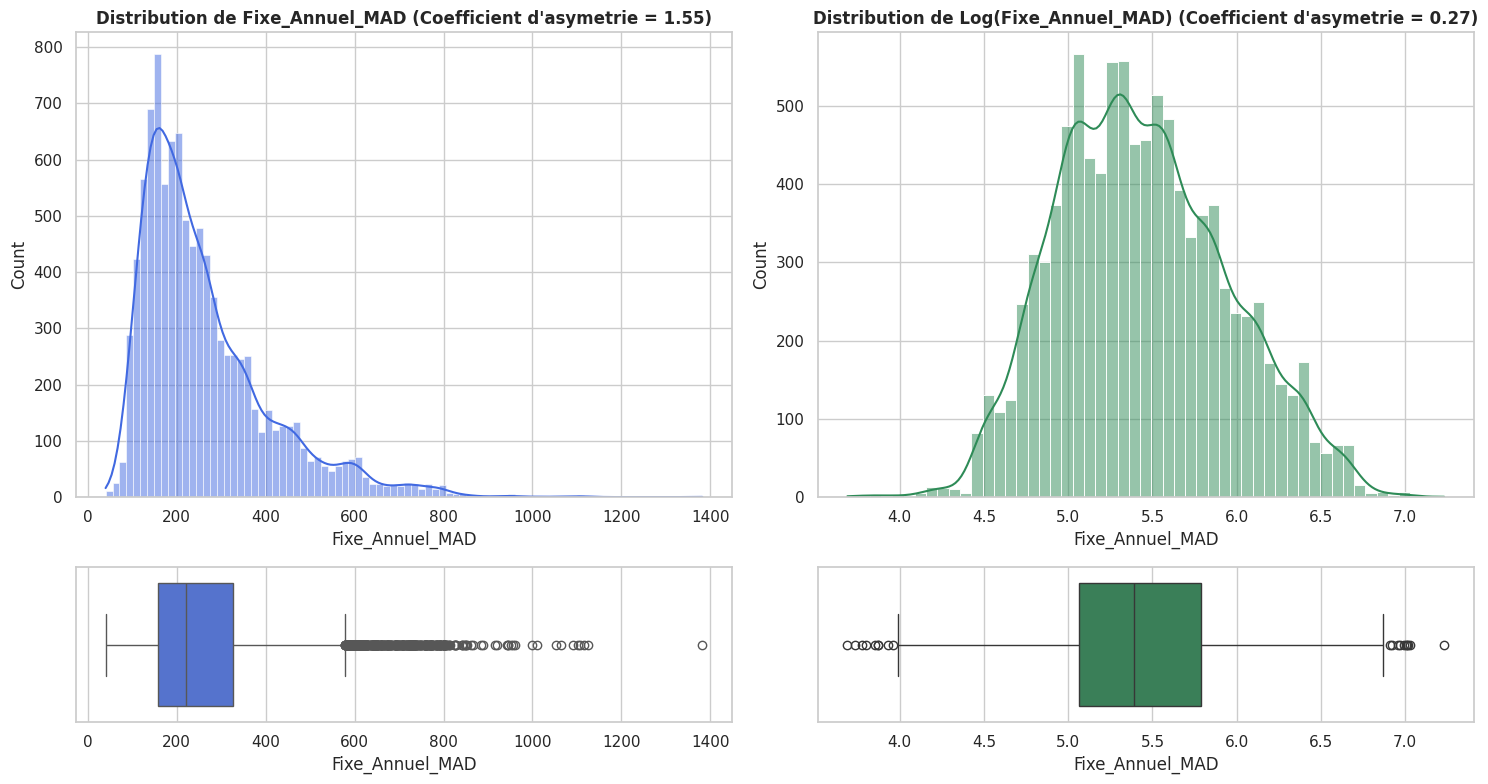

Indicateur de reference : plus le coefficient d'asymetrie (skewness) est proche de 0, plus la distribution est symetrique.


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), gridspec_kw={'height_ratios': [3, 1]})

# Distribution du salaire brut
sns.histplot(df['Fixe_Annuel_MAD'], kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title(f"Distribution de Fixe_Annuel_MAD (Coefficient d'asymetrie = {df['Fixe_Annuel_MAD'].skew():.2f})")
sns.boxplot(x=df['Fixe_Annuel_MAD'], ax=axes[1, 0], color='royalblue')

# Distribution du logarithme du salaire
log_sal = np.log(df['Fixe_Annuel_MAD'])
sns.histplot(log_sal, kde=True, ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title(f"Distribution de Log(Fixe_Annuel_MAD) (Coefficient d'asymetrie = {log_sal.skew():.2f})")
sns.boxplot(x=log_sal, ax=axes[1, 1], color='seagreen')

plt.tight_layout()
plt.show()

print("Indicateur de reference : plus le coefficient d'asymetrie (skewness) est proche de 0, plus la distribution est symetrique.")

en passant en pourcentage (Log), l'échelle compresse les grands écarts en dirhams du haut de la pyramide (donc beaucoup moins d'outliers à droite) et met en évidence les petits salaires qui sont, en proportion, trois à quatre fois plus bas que le cœur de l'entreprise (d'où les quelques outliers qui apparaissent à gauche)

---
## Visualisation 2 : Alignement des Rémunérations avec l'Architecture des Grades, les Grilles Internes et le Marché

### Objectif analytique
Cette double visualisation confronte les salaires réellement pratiqués aux repères de notre politique de rémunération (`Min`, `Mid`, `Max`) ainsi qu'à la médiane du marché (`Median`), grade par grade.

### Grille de lecture
1. **Progression par Grade (Graphique de gauche) :** On observe la pente de progression salariale d'un grade à l'autre ainsi que l'écart éventuel entre notre milieu de grille (`Mid`, courbe bleue) et le marché (`Median`, courbe rouge).
2. **Respect des bornes salariales (Graphique de droite - Range Penetration) :**
   * Une valeur inférieure à `0.0` signale les collaborateurs rémunérés sous le minimum de leur bande (*Green Circles*).
   * Une valeur égale à `0.5` correspond exactement au milieu de grille (`Mid`).
   * Une valeur supérieure à `1.0` identifie les collaborateurs dépassant le plafond de leur grade (*Red Circles*).

### Arbitrage de modélisation
* Le milieu de grille (`Mid`) et la médiane marché (`Median`) synthétisent déjà le croisement entre le niveau de responsabilité (`Grade`) et le métier (`Job_Family`). Ils constitueront le socle d'ancrage de la régression.
* L'examen des collaborateurs hors bornes nous permet de décider si certains cas extrêmes relèvent d'anomalies ponctuelles à écarter de l'échantillon d'apprentissage pour ne pas biaiser l'estimation.

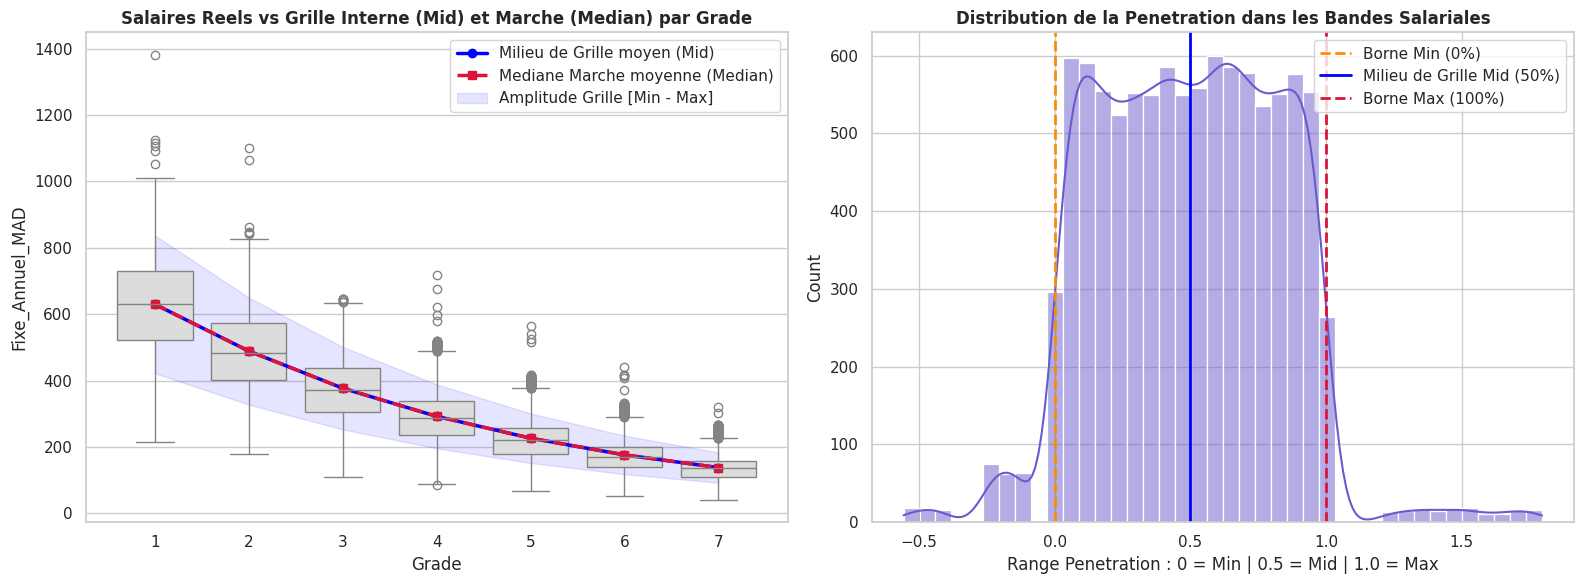

Synthese : 250 collaborateurs sous le Min (2.5%) | 150 collaborateurs au-dessus du Max (1.5%).


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Progression par Grade face a la grille et au marche
grade_order = sorted(df['Grade'].dropna().unique())
sns.boxplot(data=df, x='Grade', y='Fixe_Annuel_MAD', order=grade_order, color='gainsboro', ax=axes[0], showfliers=True)

ref_grade = df.groupby('Grade')[['Min', 'Mid', 'Max', 'Median']].mean().reindex(grade_order).reset_index()
axes[0].plot(range(len(grade_order)), ref_grade['Mid'], color='blue', marker='o', linewidth=2.5, label='Milieu de Grille moyen (Mid)')
axes[0].plot(range(len(grade_order)), ref_grade['Median'], color='crimson', marker='s', linestyle='--', linewidth=2.5, label='Mediane Marche moyenne (Median)')
axes[0].fill_between(range(len(grade_order)), ref_grade['Min'], ref_grade['Max'], color='blue', alpha=0.1, label='Amplitude Grille [Min - Max]')
axes[0].set_title('Salaires Reels vs Grille Interne (Mid) et Marche (Median) par Grade')
axes[0].legend()

# Graphique 2 : Penetration de bande salariale
sns.histplot(df['Range_Penetration'].dropna(), bins=40, kde=True, color='slateblue', ax=axes[1])
axes[1].axvline(0.0, color='darkorange', linestyle='--', linewidth=2, label='Borne Min (0%)')
axes[1].axvline(0.5, color='blue', linestyle='-', linewidth=2, label='Milieu de Grille Mid (50%)')
axes[1].axvline(1.0, color='crimson', linestyle='--', linewidth=2, label='Borne Max (100%)')
axes[1].set_title('Distribution de la Penetration dans les Bandes Salariales')
axes[1].set_xlabel('Range Penetration : 0 = Min | 0.5 = Mid | 1.0 = Max')
axes[1].legend()

plt.tight_layout()
plt.show()

sous_min = (df['Fixe_Annuel_MAD'] < df['Min']).sum()
sur_max = (df['Fixe_Annuel_MAD'] > df['Max']).sum()
print(f"Synthese : {sous_min} collaborateurs sous le Min ({sous_min/len(df)*100:.1f}%) | {sur_max} collaborateurs au-dessus du Max ({sur_max/len(df)*100:.1f}%).")

---
## Visualisation 3 : Analyse par Famille de Métier (`Job_Family`) et Compétitivité des Grilles

### Objectif analytique
Bien que chaque famille de métier dispose de sa propre grille (`Mid`), nous cherchons ici à vérifier si certaines filières métiers se positionnent systématiquement plus haut dans leur bande salariale que d'autres, et si ce phénomène s'explique par un décalage entre notre grille interne et la réalité du marché (`Mid / Median`).

### Grille de lecture
* **Graphique supérieur (`Compa-Ratio = Salaire / Mid`) :** Mesure le positionnement réel des équipes par rapport au milieu de leur grille interne (cible théorique = `1.0`).
* **Graphique inférieur (`Ratio_Grille_Marche = Mid / Median`) :** Mesure la compétitivité faciale de nos grilles par rapport au marché externe. Lorsqu'une grille interne est en retrait face au marché (`Mid / Median < 1.0`), la pression au recrutement pousse souvent les salaires réels vers le haut de la grille (`Compa-Ratio > 1.0`).

### Arbitrage de modélisation
* Si des écarts de Compa-Ratio apparaissent entre les familles de métiers, l'inclusion conjointe de `Job_Family` et du ratio structurel `Ratio_Grille_Marche` (`Mid / Median`) dans la régression est indispensable pour capter ces pratiques différenciées.

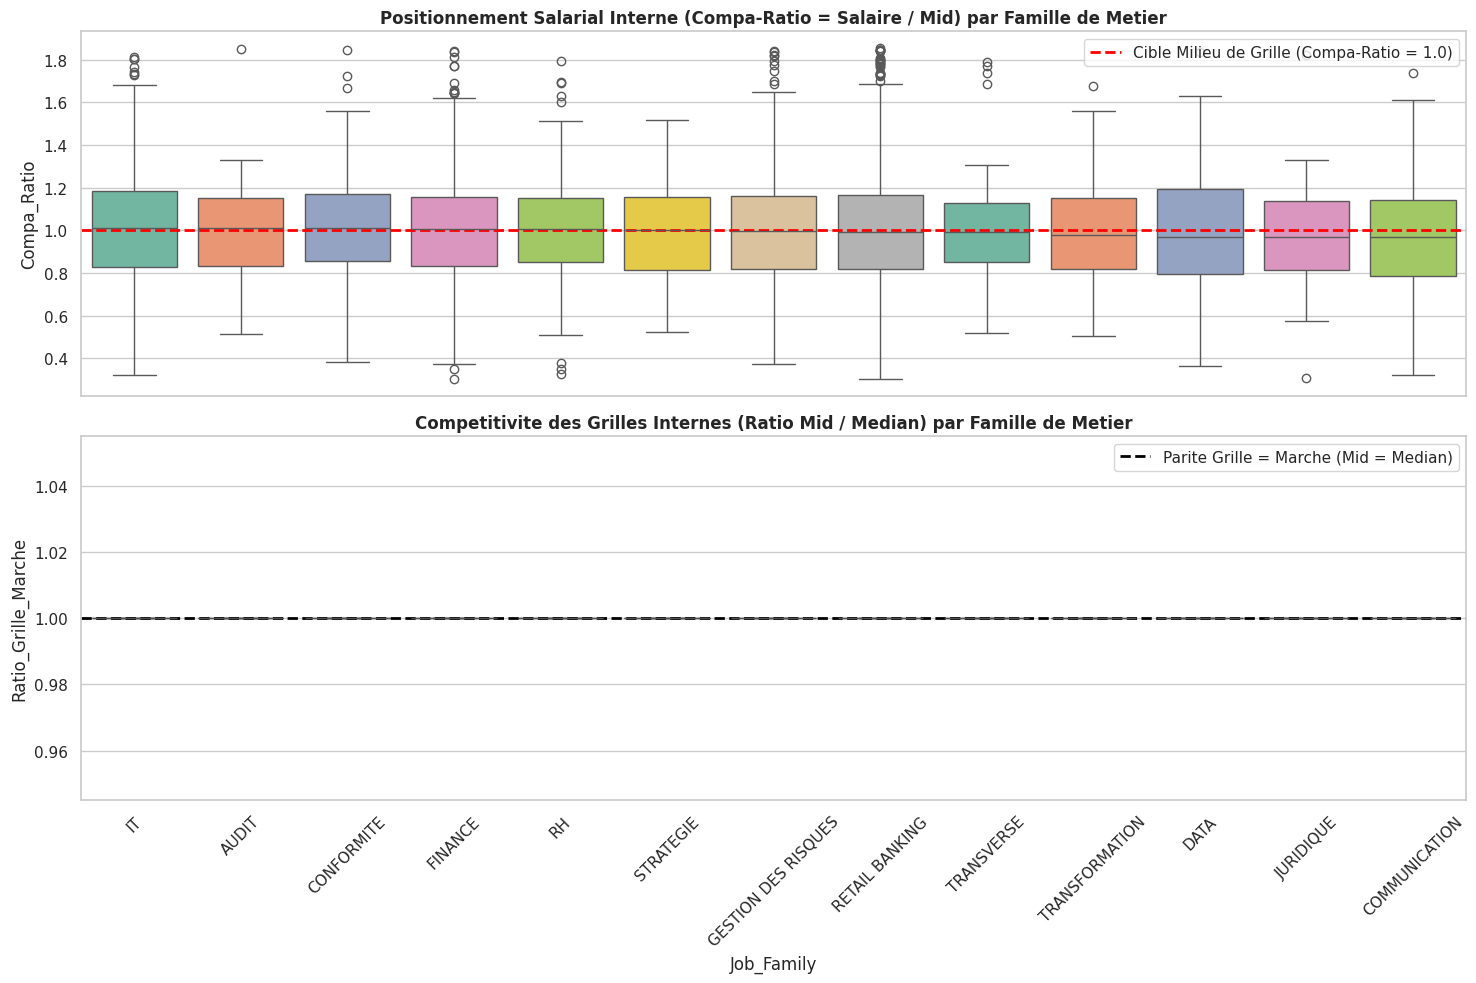

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

order_jf = df.groupby('Job_Family')['Compa_Ratio'].median().sort_values(ascending=False).index

# Graphique 1 : Compa-Ratio par famille de metier
sns.boxplot(data=df, x='Job_Family', y='Compa_Ratio', order=order_jf, palette='Set2', ax=axes[0])
axes[0].axhline(1.0, color='red', linestyle='--', linewidth=2, label='Cible Milieu de Grille (Compa-Ratio = 1.0)')
axes[0].set_title('Positionnement Salarial Interne (Compa-Ratio = Salaire / Mid) par Famille de Metier')
axes[0].legend()

# Graphique 2 : Competitivite de la grille interne face au marche
sns.boxplot(data=df, x='Job_Family', y='Ratio_Grille_Marche', order=order_jf, palette='coolwarm', ax=axes[1])
axes[1].axhline(1.0, color='black', linestyle='--', linewidth=2, label='Parite Grille = Marche (Mid = Median)')
axes[1].set_title('Competitivite des Grilles Internes (Ratio Mid / Median) par Famille de Metier')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Visualisation 4 : Séniorité (`Age`, `Anciennete`) et Détection de la Compression Salariale

### Objectif analytique
L'analyse conjointe de l'âge et de l'ancienneté répond à deux enjeux majeurs :
1. **Traitement de la colinéarité :** L'âge et l'ancienneté évoluent mécaniquement dans le même sens. Leur introduction simultanée à l'état brut dégrade la précision des coefficients de régression. En créant la variable `Age_Embauche = Age - Anciennete`, nous isolons d'un côté l'expérience acquise *antérieurement à l'embauche*, et de l'autre la séniorité acquise *en interne*.
2. **Analyse des rendements d'ancienneté et de la compression :** La courbe de tendance non-linéaire (*Lowess*) permet de vérifier si la progression dans la grille ralentit après un certain nombre d'années ou s'il existe un phénomène de compression salariale (nouveaux recrutés embauchés à des niveaux supérieurs aux collaborateurs ayant 2 à 4 ans d'ancienneté).

### Grille de lecture
* **Graphique de gauche (`Anciennete` vs `Compa-Ratio`) :** Une inflexion ou un plafonnement de la courbe rouge indique un rendement marginal décroissant de l'ancienneté. Une pente initiale négative entre 0 et 3 ans signale une compression salariale à l'embauche.
* **Graphique de droite (`Age_Embauche` vs `Compa-Ratio`) :** Évalue comment l'expérience externe préalable est valorisée dans la bande salariale.

### Arbitrage de modélisation
* Substitution du couple `(Age, Anciennete)` par le couple orthogonal `(Age_Embauche, Anciennete)`.
* Ajout d'un terme quadratique (`Anciennete²`) dans la régression si la courbe de gauche présente un plafonnement marqué.

Le graphe pose donc la question : à poste égal, est-on mieux placé dans sa grille selon l'ancienneté (à gauche) ou selon l'âge à l'embauche (à droite) ?

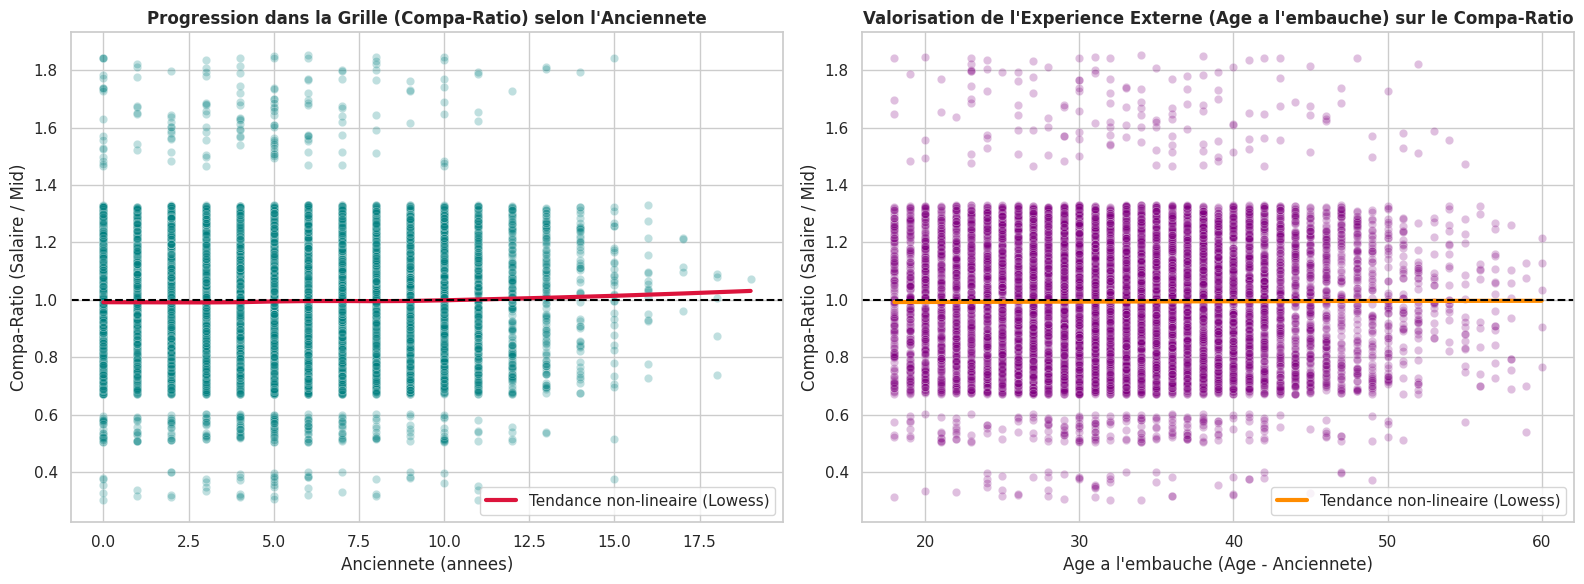

Correlation lineaire brute Age / Anciennete         : 0.09
Correlation apres retraitement Age_Embauche / Anciennete : -0.37


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Anciennete vs Compa-Ratio
sns.scatterplot(data=df, x='Anciennete', y='Compa_Ratio', alpha=0.25, color='teal', ax=axes[0])
sns.regplot(data=df, x='Anciennete', y='Compa_Ratio', scatter=False, lowess=True, color='crimson', line_kws={'linewidth': 3}, ax=axes[0], label='Tendance non-lineaire (Lowess)')
axes[0].axhline(1.0, color='black', linestyle='--')
axes[0].set_title('Progression dans la Grille (Compa-Ratio) selon l\'Anciennete')
axes[0].set_xlabel('Anciennete (annees)')
axes[0].set_ylabel('Compa-Ratio (Salaire / Mid)')
axes[0].legend()

# Graphique 2 : Age a l'embauche vs Compa-Ratio
sns.scatterplot(data=df, x='Age_Embauche', y='Compa_Ratio', alpha=0.25, color='purple', ax=axes[1])
sns.regplot(data=df, x='Age_Embauche', y='Compa_Ratio', scatter=False, lowess=True, color='darkorange', line_kws={'linewidth': 3}, ax=axes[1], label='Tendance non-lineaire (Lowess)')
axes[1].axhline(1.0, color='black', linestyle='--')
axes[1].set_title('Valorisation de l\'Experience Externe (Age a l\'embauche) sur le Compa-Ratio')
axes[1].set_xlabel('Age a l\'embauche (Age - Anciennete)')
axes[1].set_ylabel('Compa-Ratio (Salaire / Mid)')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Correlation lineaire brute Age / Anciennete         : {df['Age'].corr(df['Anciennete']):.2f}")
print(f"Correlation apres retraitement Age_Embauche / Anciennete : {df['Age_Embauche'].corr(df['Anciennete']):.2f}")

---
## Visualisation 5 : Différenciation par la Performance (`Competence_N1`, `Positionnement_9BOX`) et la Tension Métier (`Hot_job`)

### Objectif analytique
Nous vérifions ici dans quelle mesure les éléments individuels de performance/potentiel (`Competence_N1`, `Positionnement_9BOX`) et la rareté du poste sur le marché (`Hot_job`) se traduisent par une différenciation salariale effective au sein des grilles.

### Grille de lecture
* **Matrice de gauche (Croisement `Positionnement_9BOX` x `Hot_job`) :** Indique le Compa-Ratio moyen pour chaque segment. Une politique de rétention ciblée se traduit par des valeurs plus élevées dans le quadrant supérieur droit (fort potentiel/performance sur un métier en forte tension, `Hot_job = 2`).
* **Graphique de droite (`Competence_N1` vs `Compa-Ratio`) :** La pente des droites mesure la sensibilité du salaire à l'évaluation des compétences de l'année précédente, selon le niveau de tension du métier.

### Arbitrage de modélisation
* Intégration de `Competence_N1`, `Positionnement_9BOX` et `Hot_job`.
* Si la matrice de gauche révèle un effet multiplicatif sur les profils à haut potentiel occupant des postes critiques, nous intégrerons un terme d'interaction explicite (`Positionnement_9BOX * Hot_job`).

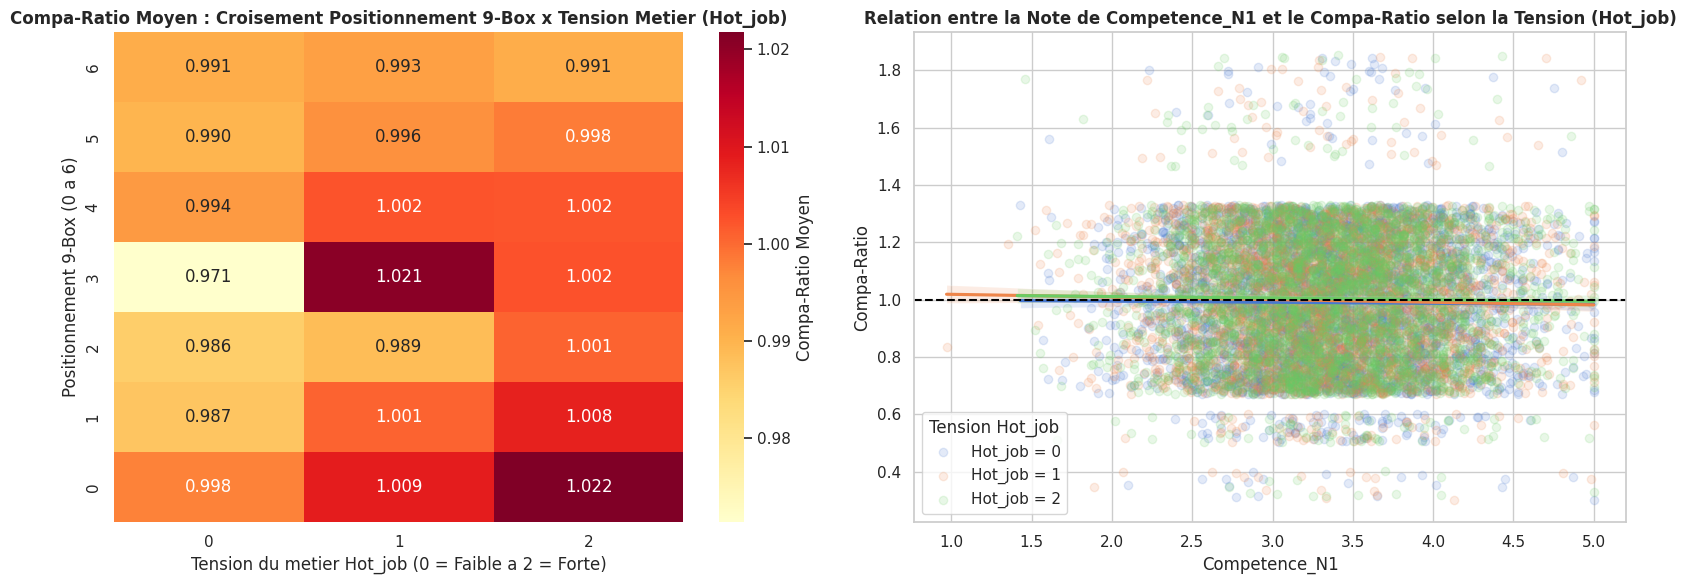

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Matrice Compa-Ratio moyen par 9-Box et Hot_job
pivot_9box = df.pivot_table(index='Positionnement_9BOX', columns='Hot_job', values='Compa_Ratio', aggfunc='mean')
pivot_9box = pivot_9box.sort_index(ascending=False)
sns.heatmap(pivot_9box, annot=True, fmt='.3f', cmap='YlOrRd', cbar_kws={'label': 'Compa-Ratio Moyen'}, ax=axes[0])
axes[0].set_title('Compa-Ratio Moyen : Croisement Positionnement 9-Box x Tension Metier (Hot_job)')
axes[0].set_ylabel('Positionnement 9-Box (0 a 6)')
axes[0].set_xlabel('Tension du metier Hot_job (0 = Faible a 2 = Forte)')

# Graphique 2 : Competence N-1 vs Compa-Ratio par niveau de tension (en utilisant regplot sur axes[1])
colors = ['#440154', '#31688e', '#fde725'] # Couleurs personnalisées pour Hot_job (0, 1, 2)
for hj_val in sorted(df['Hot_job'].unique()):
    subset = df[df['Hot_job'] == hj_val]
    sns.regplot(
        data=subset,
        x='Competence_N1',
        y='Compa_Ratio',
        scatter_kws={'alpha':0.15},
        ax=axes[1],
        label=f'Hot_job = {hj_val}'
    )

axes[1].axhline(1.0, color='black', linestyle='--')
axes[1].set_title('Relation entre la Note de Competence_N1 et le Compa-Ratio selon la Tension (Hot_job)')
axes[1].set_xlabel('Competence_N1')
axes[1].set_ylabel('Compa-Ratio')
axes[1].legend(title='Tension Hot_job')

plt.tight_layout()
plt.show()

---
## Visualisation 6 : Analyse de l'Équité Interne (`Sexe`) et des Pratiques par Pôle (`Entite_N1`)

### Objectif analytique
1. **Équité professionnelle (`Sexe`) :** Une comparaison globale des salaires moyens entre hommes et femmes est souvent biaisée par des effets de structure (répartition par grade ou par filière métier). La comparaison du `Compa_Ratio` à grade identique permet d'isoler l'écart résiduel à périmètre de responsabilité comparable.
2. **Effet organisationnel (`Entite_N1`) :** L'examen du `Compa-Ratio` par Pôle neutralise la structure des emplois et met en lumière d'éventuelles différences d'historique budgétaire entre les entités.

### Grille de lecture
* **Graphique de gauche :** Alignement des distributions F et M au sein de chaque grade.
* **Graphique de droite :** Dispersion des médianes de Compa-Ratio entre les différents pôles (`Entite_N1`).

### Arbitrage de modélisation (Point d'arbitrage managérial)
* **Variable `Entite_N1` :** À inclure (encodage catégoriel) si des écarts significatifs entre pôles sont constatés.
* **Variable `Sexe` :** Deux approches selon la finalité que nous donnons au modèle :
  * *Finalité d'audit d'équité :* Inclusion de la variable `Sexe` dans la régression afin de mesurer statistiquement l'existence ou l'absence d'écart salarial toutes choses égales par ailleurs.
  * *Finalité de recommandation salariale cible :* Exclusion de la variable `Sexe` du modèle prédictif afin de garantir une neutralité absolue des prédictions.

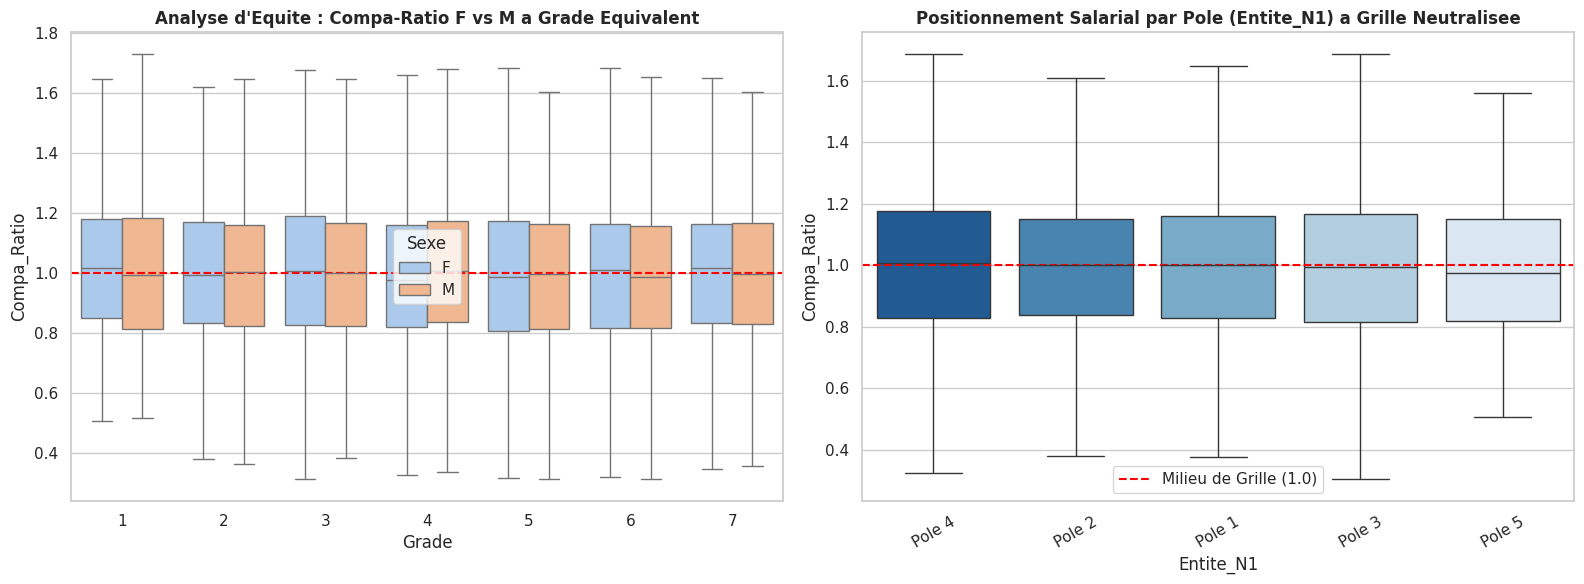

Ecart salarial moyen non corrige (M vs F)                     : -0.17%
Ecart moyen a grille et metier constants (Compa-Ratio M vs F) : -0.37%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Equite F/M par Grade
sns.boxplot(data=df, x='Grade', y='Compa_Ratio', hue='Sexe', order=grade_order, palette='pastel', showfliers=False, ax=axes[0])
axes[0].axhline(1.0, color='red', linestyle='--')
axes[0].set_title('Analyse d\'Equite : Compa-Ratio F vs M a Grade Equivalent')

# Graphique 2 : Positionnement par Pole (Entite_N1)
order_entite = df.groupby('Entite_N1')['Compa_Ratio'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Entite_N1', y='Compa_Ratio', order=order_entite, palette='Blues_r', showfliers=False, ax=axes[1])
axes[1].axhline(1.0, color='red', linestyle='--', label='Milieu de Grille (1.0)')
axes[1].set_title('Positionnement Salarial par Pole (Entite_N1) a Grille Neutralisee')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()

plt.tight_layout()
plt.show()

ecart_brut = (df[df['Sexe']=='M']['Fixe_Annuel_MAD'].mean() / df[df['Sexe']=='F']['Fixe_Annuel_MAD'].mean() - 1) * 100
ecart_compa = (df[df['Sexe']=='M']['Compa_Ratio'].mean() / df[df['Sexe']=='F']['Compa_Ratio'].mean() - 1) * 100
print(f"Ecart salarial moyen non corrige (M vs F)                     : {ecart_brut:+.2f}%")
print(f"Ecart moyen a grille et metier constants (Compa-Ratio M vs F) : {ecart_compa:+.2f}%")

---
## Visualisation 7 : Granularité Organisationnelle (`Entite_N2`) et Postes (`Job_Title`)

### Objectif analytique
Les variables `Entite_N2` et `Job_Title` présentent un niveau de détail très fin. En modélisation statistique, intégrer des variables catégorielles comportant un grand nombre de modalités à très faibles effectifs (moins de 5 collaborateurs par poste ou par sous-entité) entraîne un phénomène de surapprentissage (*overfitting*) : le modèle mémorise des situations individuelles au lieu d'extraire une règle générale.

### Grille de lecture
* Les histogrammes ci-dessous présentent la distribution de la taille des effectifs par `Entite_N2` et par `Job_Title`, ainsi que la proportion de modalités comptant moins de 5 collaborateurs.

### Arbitrage de modélisation
* **Exclusion de `Job_Title` :** Les caractéristiques structurantes d'un poste sont déjà intégralement captées par `Job_Family`, `Grade`, `Mid`, `Median` et `Hot_job` (qui est constant par poste). L'exclusion de `Job_Title` garantit la robustesse du modèle.
* **Arbitrage `Entite_N1` vs `Entite_N2` :** Si une part importante des `Entite_N2` comporte moins de 5 salariés, il est préférable de retenir `Entite_N1` pour assurer la stabilité des estimations.

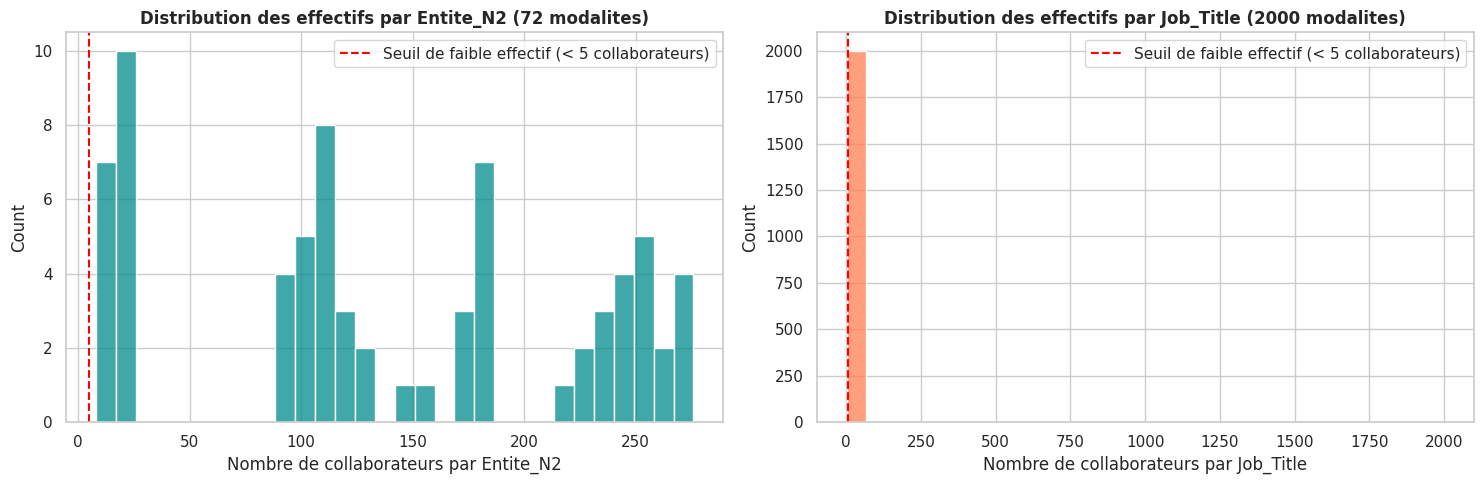

Entite_N2 comptant moins de 5 collaborateurs : 0 sur 72 (0.0%)
Job_Title comptant moins de 5 collaborateurs : 1286 sur 2000 (64.3%)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

counts_en2 = df['Entite_N2'].value_counts()
sns.histplot(counts_en2, bins=30, color='darkcyan', ax=axes[0])
axes[0].axvline(5, color='red', linestyle='--', label='Seuil de faible effectif (< 5 collaborateurs)')
axes[0].set_title(f"Distribution des effectifs par Entite_N2 ({len(counts_en2)} modalites)")
axes[0].set_xlabel("Nombre de collaborateurs par Entite_N2")
axes[0].legend()

counts_jt = df['Job_Title'].value_counts()
sns.histplot(counts_jt, bins=30, color='coral', ax=axes[1])
axes[1].axvline(5, color='red', linestyle='--', label='Seuil de faible effectif (< 5 collaborateurs)')
axes[1].set_title(f"Distribution des effectifs par Job_Title ({len(counts_jt)} modalites)")
axes[1].set_xlabel("Nombre de collaborateurs par Job_Title")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Entite_N2 comptant moins de 5 collaborateurs : {(counts_en2 < 5).sum()} sur {len(counts_en2)} ({(counts_en2 < 5).mean()*100:.1f}%)")
print(f"Job_Title comptant moins de 5 collaborateurs : {(counts_jt < 5).sum()} sur {len(counts_jt)} ({(counts_jt < 5).mean()*100:.1f}%)")

---
## Visualisation 8 : Contrôle de la Multicolinéarité (Matrice de Corrélation et Facteur d'Inflation de la Variance - VIF)

### Objectif analytique
Avant d'estimer l'équation de régression, nous devons vérifier l'absence de redondance forte entre les variables explicatives (multicolinéarité). En particulier, les bornes de grille (`Min`, `Mid`, `Max`), la médiane marché (`Median`) et le `Grade` évoluent de concert. L'indicateur statistique de référence est le **VIF (*Variance Inflation Factor*)** :
* **VIF < 5 :** Absence de colinéarité problématique, les estimations des coefficients sont stables.
* **VIF > 10 :** Forte redondance statistique qui fausse la lecture individuelle des coefficients.

### Grille de lecture
* **Premier tableau VIF (Variables brutes) :** Met en évidence la redondance mécanique entre `Min`, `Mid`, `Max`, `Median`, `Grade`, `Age` et `Anciennete`.
* **Second tableau VIF (Sélection retraitée) :** Démontre qu'en conservant `Mid` comme point d'ancrage, complété par le ratio relatif `Ratio_Grille_Marche` (`Mid / Median`) et par `Age_Embauche`, tous les indicateurs VIF passent sous le seuil de tolérance (< 5).

### Arbitrage de modélisation
* Validation du périmètre retraité (second tableau) qui préserve l'intégralité de l'information économique tout en garantissant l'interprétabilité des poids de chaque variable.

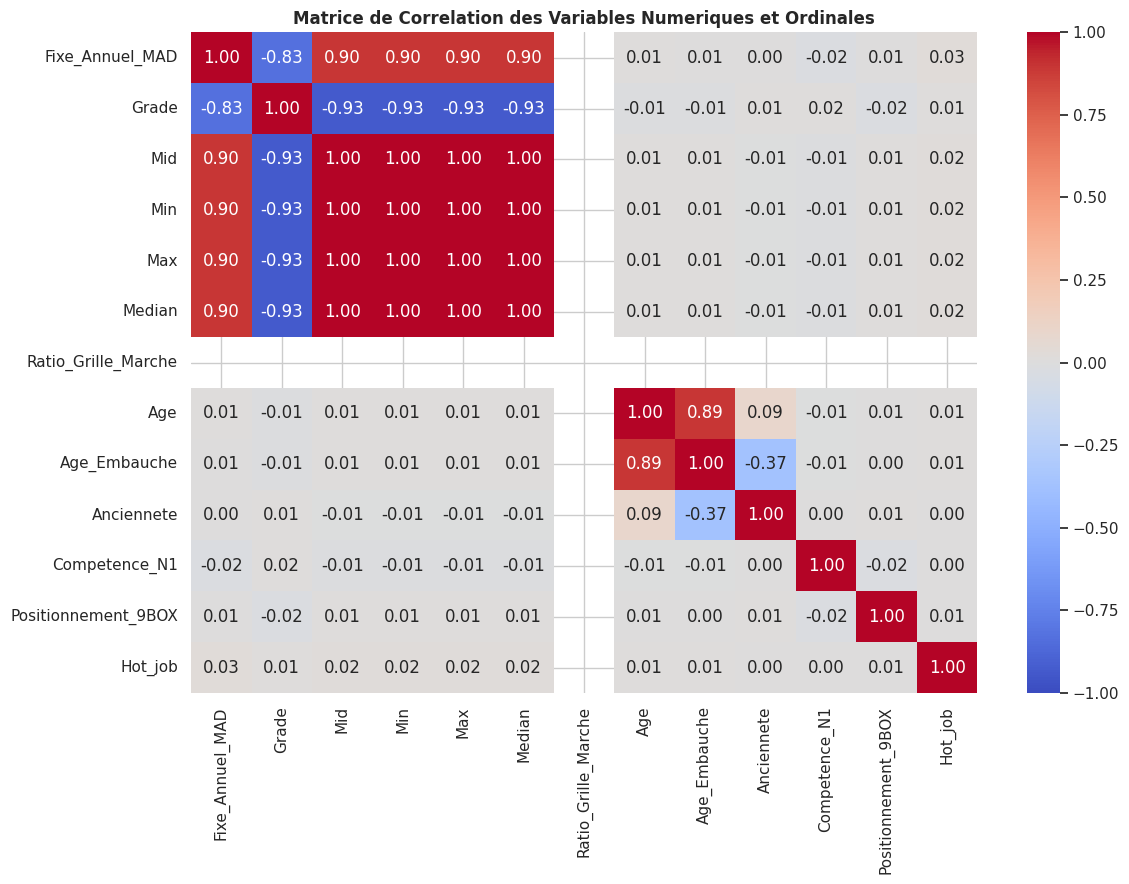

1. DIAGNOSTIC VIF SUR VARIABLES BRUTES (Colinearite elevee) :


,Variable,VIF
4,Median,1.000800e+15
2,Mid,1.000800e+15
3,Max,1.219863e+10
1,Min,3.533876e+09
0,Grade,8.667843e+00
9,Hot_job,1.008507e+00
6,Anciennete,1.007938e+00
5,Age,1.007936e+00
8,Positionnement_9BOX,1.001924e+00
7,Competence_N1,1.000942e+00



2. DIAGNOSTIC VIF SUR VARIABLES RETRAITEES (Stabilite statistique, VIF < 5) :
Colonnes sans variation, ecartees du calcul VIF : ['Ratio_Grille_Marche']


,Variable,VIF
1,Age_Embauche,1.159847
2,Anciennete,1.159761
4,Positionnement_9BOX,1.000846
0,Mid,1.000839
3,Competence_N1,1.000713
5,Hot_job,1.000591


In [15]:
# 1. Matrice de correlation lineaire
cols_corr = ['Fixe_Annuel_MAD', 'Grade', 'Mid', 'Min', 'Max', 'Median',
             'Ratio_Grille_Marche', 'Age', 'Age_Embauche', 'Anciennete',
             'Competence_N1', 'Positionnement_9BOX', 'Hot_job']

plt.figure(figsize=(12, 9))
sns.heatmap(df[cols_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matrice de Correlation des Variables Numeriques et Ordinales')
plt.tight_layout()
plt.show()

# 2. Calcul comparatif des VIF
def calc_vif(data, cols):
    X = data[cols].dropna().copy()
    # Une colonne qui ne varie pas (ex. Ratio_Grille_Marche quand la grille est egale au marche) n'apporte
    # aucune information, et statsmodels la prend pour la constante : on l'ecarte et on le signale
    constantes = [col for col in X.columns if X[col].nunique() <= 1]
    if constantes:
        print(f"Colonnes sans variation, ecartees du calcul VIF : {constantes}")
        X = X.drop(columns=constantes)
    # has_constant='add' : la constante est toujours ajoutee, donc toujours en position 0
    X_const = sm.add_constant(X, has_constant='add')
    vif = pd.DataFrame()
    vif['Variable'] = X.columns
    vif['VIF'] = [variance_inflation_factor(X_const.values, i+1) for i in range(len(X.columns))]
    return vif.sort_values(by='VIF', ascending=False)

cols_brutes = ['Grade', 'Min', 'Mid', 'Max', 'Median', 'Age', 'Anciennete', 'Competence_N1', 'Positionnement_9BOX', 'Hot_job']
cols_propres = ['Mid', 'Ratio_Grille_Marche', 'Age_Embauche', 'Anciennete', 'Competence_N1', 'Positionnement_9BOX', 'Hot_job']

print("1. DIAGNOSTIC VIF SUR VARIABLES BRUTES (Colinearite elevee) :")
display(calc_vif(df, cols_brutes))

print("\n2. DIAGNOSTIC VIF SUR VARIABLES RETRAITEES (Stabilite statistique, VIF < 5) :")
display(calc_vif(df, cols_propres))

---
## Étape Finale : Estimation du Modèle de Régression, Validation Croisée et Restitution

### Objectif de cette section
Sur la base des constats précédents, cette dernière étape exécute l'estimation économétrique et évalue la précision prédictive du jeu de variables retenu :
1. **Estimation OLS (`statsmodels`) :** Permet de consulter le poids exact de chaque facteur (`coef`) et sa significativité statistique (`P>|t| < 0.05`).
2. **Benchmark en Validation Croisée (5-Fold) :** Compare un modèle linéaire régularisé (**Ridge**) et un modèle d'arbres non-linéaire (**Gradient Boosting**) selon trois métriques : le coefficient de détermination ($R^2$), l'erreur absolue moyenne en kMAD (MAE) et l'erreur relative moyenne en pourcentage (MAPE).
3. **Génération de la table finale :** Restitue l'ensemble des colonnes d'origine (y compris `Pays`, `FTE`, `Devise`, `Date_Effet_Paie`), le salaire théorique prédit par le modèle et l'écart relatif individuel pour appuyer les revues salariales.

In [21]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

# --- PARAMETRES D'ARBITRAGE ---
INCLURE_SEXE = False          # True pour un audit d'equite, False pour un modele de recommandation neutre
UTILISER_LOG_SALAIRE = True   # True pour modeliser en % d'evolution (Log), False pour modeliser en kMAD bruts

# 1. Preparation de la matrice de modelisation
df_model = df.dropna(subset=['Fixe_Annuel_MAD', 'Mid', 'Median']).copy()
df_model['Log_Mid'] = np.log(df_model['Mid'])
df_model['Anciennete_Carre'] = df_model['Anciennete'] ** 2
df_model['Interaction_9BOX_HotJob'] = df_model['Positionnement_9BOX'] * df_model['Hot_job']

num_features = [
    'Log_Mid',                  # Positionnement théorique de la grille interne (Grade x Job_Family)
    'Ratio_Grille_Marche',      # Compétitivité de la grille par rapport au marché (Mid / Median)
    'Anciennete',               # Ancienneté dans l'entreprise
    'Anciennete_Carre',         # Terme quadratique captant l'inflexion des rendements d'ancienneté
    'Age_Embauche',             # Proxy de l'expérience externe préalable à l'embauche
    'Competence_N1',            # Évaluation des compétences N-1
    'Positionnement_9BOX',      # Grille de performance / potentiel
    'Hot_job',                  # Indicateur de tension marché sur le poste
    'Interaction_9BOX_HotJob'   # Terme croisé (Performance/Potentiel x Tension marché)
]

cat_features = ['Entite_N1', 'Job_Family']
if INCLURE_SEXE:
    cat_features.append('Sexe')

# 2. Estimation econometrique explicable (OLS)
X_ols = pd.get_dummies(df_model[num_features + cat_features], drop_first=True, dtype=float)
# Une colonne qui ne varie pas n'apporte rien et prendrait la place de la constante : on l'ecarte
sans_variation = [c for c in X_ols.columns if X_ols[c].nunique() <= 1]
X_ols = sm.add_constant(X_ols.drop(columns=sans_variation), has_constant='add')
y_ols = np.log(df_model['Fixe_Annuel_MAD']) if UTILISER_LOG_SALAIRE else df_model['Fixe_Annuel_MAD']
modele_ols = sm.OLS(y_ols, X_ols).fit()
# print(modele_ols.summary())  # detail complet, si besoin

# Synthese : une ligne par variable, avec un verdict clair
def effet(coef):
    return f"{np.exp(coef) - 1:+.1%}" if UTILISER_LOG_SALAIRE else f"{coef:+.2f} kMAD"

lignes = []
for variable in num_features + cat_features:
    colonnes = [c for c in X_ols.columns if c == variable or c.startswith(variable + '_')]
    if not colonnes:
        lignes.append((variable, '-', np.nan, 'A retirer (ne varie pas)'))
        continue
    if variable in cat_features:
        # Pole, metier : un seul test pour toutes les colonnes 0/1 du groupe
        R = np.zeros((len(colonnes), len(modele_ols.params)))
        for i, c in enumerate(colonnes):
            R[i, modele_ols.params.index.get_loc(c)] = 1
        p = float(modele_ols.f_test(R).pvalue)
        coefs = modele_ols.params[colonnes]
        texte = f"de {effet(min(coefs.min(), 0))} a {effet(max(coefs.max(), 0))} selon la valeur"
    else:
        p = modele_ols.pvalues[variable]
        coef = modele_ols.params[variable]
        texte = f"+1 % de Mid = {coef:+.2f} %" if variable == 'Log_Mid' else f"+1 = {effet(coef)}"
    verdict = 'A GARDER' if p < 0.01 else ('A confirmer (effet faible)' if p < 0.05 else 'A retirer')
    lignes.append((variable, texte, p, verdict))

synthese = pd.DataFrame(lignes, columns=['Variable', 'Effet sur le salaire', 'P(proba que ce soit du au hasard)', 'Verdict'])
ordre = {'A GARDER': 0, 'A confirmer (effet faible)': 1, 'A retirer': 2, 'A retirer (ne varie pas)': 3}
synthese = synthese.sort_values(['Verdict', 'P(proba que ce soit du au hasard)'], key=lambda s: s.map(ordre) if s.name == 'Verdict' else s)
print("QUELLES VARIABLES GARDER ?")
display(synthese.set_index('Variable').round({'P(proba que ce soit du au hasard)': 3}))
print("Variables a garder :", synthese.loc[synthese['Verdict'] == 'A GARDER', 'Variable'].tolist())

QUELLES VARIABLES GARDER ?


,Effet sur le salaire,P(proba que ce soit du au hasard),Verdict
Variable,,,
Log_Mid,+1 % de Mid = +1.00 %,0.000,A GARDER
Hot_job,+1 = +1.2%,0.026,A confirmer (effet faible)
Competence_N1,+1 = -0.7%,0.080,A retirer
Anciennete_Carre,+1 = +0.0%,0.109,A retirer
Interaction_9BOX_HotJob,+1 = -0.2%,0.242,A retirer
Age_Embauche,+1 = +0.0%,0.277,A retirer
Anciennete,+1 = -0.2%,0.424,A retirer
Job_Family,de -1.8% a +8.1% selon la valeur,0.792,A retirer
Entite_N1,de -7.6% a +0.0% selon la valeur,0.832,A retirer


Variables a garder : ['Log_Mid']


In [19]:
# 3. Evaluation predictive en Validation Croisee (5-Fold)
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_features)
])

pipe_ridge = Pipeline([('prep', preprocessor), ('reg', Ridge(alpha=1.0))])
pipe_gbm = Pipeline([('prep', preprocessor), ('reg', HistGradientBoostingRegressor(max_depth=5, random_state=42))])

kf = KFold(n_splits=5, shuffle=True, random_state=42)
X_sk = df_model[num_features + cat_features]
y_true_mad = df_model['Fixe_Annuel_MAD'].values

for nom, pipe in [('Regression Lineaire Regularisee (Ridge)', pipe_ridge),
                  ('Gradient Boosting (HistGBM)', pipe_gbm)]:
    preds = cross_val_predict(pipe, X_sk, y_ols, cv=kf)
    preds_mad = np.exp(preds) if UTILISER_LOG_SALAIRE else preds

    r2 = r2_score(y_true_mad, preds_mad)
    mae = mean_absolute_error(y_true_mad, preds_mad)
    mape = mean_absolute_percentage_error(y_true_mad, preds_mad) * 100
    print(f"\nPerformance en Validation Croisee (5-Fold) - {nom} :")
    print(f"  - R2 (Variance expliquee)        : {r2*100:.2f}%")
    print(f"  - MAE (Erreur absolue moyenne)   : {mae:.2f} kMAD")
    print(f"  - MAPE (Erreur relative moyenne) : {mape:.2f}%")

# 4. Consolidation du fichier de sortie avec restitution des colonnes administratives
pipe_ridge.fit(X_sk, y_ols)
pred_final = pipe_ridge.predict(X_sk)
df_model['Salaire_Predit_kMAD'] = np.round(np.exp(pred_final) if UTILISER_LOG_SALAIRE else pred_final, 2)
df_model['Ecart_Salaire_vs_Predit_Pct'] = np.round((df_model['Fixe_Annuel_MAD'] / df_model['Salaire_Predit_kMAD'] - 1) * 100, 2)

cols_export = [c for c in ['Matricule', 'Nom', 'Pays', 'FTE', 'Devise', 'Date_Effet_Paie',
                           'Entite_N1', 'Entite_N2', 'Job_Family', 'Job_Title', 'Grade',
                           'Fixe_Annuel_MAD', 'Salaire_Predit_kMAD', 'Ecart_Salaire_vs_Predit_Pct',
                           'Min', 'Mid', 'Max', 'Median', 'Compa_Ratio'] if c in df_model.columns]

df_resultats = df_model[cols_export]
# Pour generer l'export Excel final, decommentez la ligne suivante :
# df_resultats.to_excel('Resultats_Positionnement_Salarial.xlsx', index=False)
print("\nApercu de la table de restitution finale :")
display(df_resultats.head(10))


Performance en Validation Croisee (5-Fold) - Regression Lineaire Regularisee (Ridge) :
  - R2 (Variance expliquee)        : 79.94%
  - MAE (Erreur absolue moyenne)   : 47.85 kMAD
  - MAPE (Erreur relative moyenne) : 19.50%

Performance en Validation Croisee (5-Fold) - Gradient Boosting (HistGBM) :
  - R2 (Variance expliquee)        : 79.35%
  - MAE (Erreur absolue moyenne)   : 48.37 kMAD
  - MAPE (Erreur relative moyenne) : 19.72%

Apercu de la table de restitution finale :


,Matricule,Nom,Pays,FTE,Devise,Date_Effet_Paie,Entite_N1,Entite_N2,Job_Family,Job_Title,Grade,Fixe_Annuel_MAD,Salaire_Predit_kMAD,Ecart_Salaire_vs_Predit_Pct,Min,Mid,Max,Median,Compa_Ratio
0,Mat00001,NaN,Maroc,1,MAD,01/08/2025,Pole 3,P3-E13,RETAIL BANKING,JT1389,5,216.40,206.65,4.72,142.67,212.94,283.21,212.94,1.016249
1,Mat00002,NaN,Maroc,1,MAD,01/08/2025,Pole 3,P3-E06,RETAIL BANKING,JT1109,3,304.48,347.63,-12.41,241.11,359.87,478.63,359.87,0.846083
2,Mat00003,NaN,Maroc,1,MAD,01/08/2025,Pole 3,P3-E01,RETAIL BANKING,JT1103,2,544.96,447.82,21.69,313.45,467.83,622.21,467.83,1.164868
3,Mat00004,NaN,Maroc,1,MAD,01/08/2025,Pole 4,P4-E03,FINANCE,JT0355,4,331.99,269.89,23.01,185.47,276.82,368.17,276.82,1.199299
4,Mat00005,NaN,Maroc,1,MAD,01/08/2025,Pole 4,P4-E05,IT,JT0939,7,197.78,195.10,1.37,134.00,200.00,266.00,200.00,0.988900
5,Mat00006,NaN,Maroc,1,MAD,01/08/2025,Pole 5,P5-E04,TRANSFORMATION,JT1945,5,242.63,205.68,17.96,142.67,212.94,283.21,212.94,1.139429
6,Mat00007,NaN,Maroc,1,MAD,01/08/2025,Pole 4,P4-E05,FINANCE,JT0493,7,88.74,122.50,-27.56,84.42,126.00,167.58,126.00,0.704286
7,Mat00008,NaN,Maroc,1,MAD,01/08/2025,Pole 3,P3-E07,RETAIL BANKING,JT1601,6,173.00,158.19,9.36,109.75,163.80,217.85,163.80,1.056166
8,Mat00009,NaN,Maroc,1,MAD,01/08/2025,Pole 5,P5-E01,TRANSFORMATION,JT1934,5,193.14,207.83,-7.07,142.67,212.94,283.21,212.94,0.907016
9,Mat00010,NaN,Maroc,1,MAD,01/08/2025,Pole 3,P3-E09,RETAIL BANKING,JT1468,5,268.05,204.08,31.35,142.67,212.94,283.21,212.94,1.258805
